# Industrial High-Temperature Heat Pumps vs Gas Boilers: COP, LCOH and the Carbon Price Needed for Parity

**Author:** Muhammad Waqas Saleem

This notebook models a single-stage industrial high-temperature heat pump (IHTHP) supplying 120–150 °C process heat. It compares the heat pump's levelised cost of heat (LCOH) with a natural gas steam boiler under EU carbon pricing and electricity/gas price scenarios.

**Research question:** under current EU energy prices, what EU ETS carbon price makes a high-temperature heat pump cost-competitive with a gas boiler, and which policy levers move that threshold the most?

Inputs come from the Danish Energy Agency technology catalogue, Eurostat, ESMA and the IPCC. See the README for the full references.

## 1. Setup

In [1]:
%pip install -q CoolProp

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

FLUID = "R1233zd(E)"
print(f"{FLUID}: critical temperature = {PropsSI('Tcrit', FLUID) - 273.15:.1f} °C")

R1233zd(E): critical temperature = 165.7 °C


## 2. Input parameters

In [3]:
# All inputs in one place. Each value has its source; full references are in the README.
P = {
    # --- Heat pump cycle ---
    "eta_isentropic": 0.70,     # compressor isentropic efficiency (typical modelling assumption)
    "pinch_K": 5.0,             # temperature approach in evaporator and condenser
    "superheat_K": 10.0,        # suction superheat (keeps compression out of the two-phase region)

    # --- Reference case (DEA 2026 worked example: 60 °C source, 80 K lift) ---
    "T_source_C": 60.0,
    "T_sink_C": 140.0,

    # --- Industrial high-temperature heat pump (DEA, Technology Data for Industrial Process Heat) ---
    "hp_capex_eur_kW": 1750.0,  # 1.55 M€/MW (HTHP up to 150 °C, 2025) + 0.20 M€/MW add-on for lift > 75 K
    "hp_fom_share": 0.000929,   # fixed O&M, 0.0929 %/yr of CAPEX (DEA 302.b via PyPSA technology-data)
    "hp_vom_eur_MWh": 4.09,     # variable O&M, €/MWh_heat (DEA 302.b via PyPSA technology-data)
    "hp_lifetime_yr": 20,       # DEA 302.b technical lifetime

    # --- Natural gas steam boiler (DEA 311.1c via PyPSA technology-data) ---
    "boiler_capex_eur_kW": 63.3,
    "boiler_fom_share": 0.039,  # 3.9 %/yr of CAPEX
    "boiler_vom_eur_MWh": 1.33,
    "boiler_efficiency": 0.925,
    "boiler_lifetime_yr": 25,

    # --- Finance and operation ---
    "discount_rate": 0.04,      # DEA catalogue real discount rate
    "full_load_hours": 5000,    # DEA industrial heat pump vs boiler example

    # --- Energy prices, EU average non-household, H2 2025, excl. VAT (Eurostat) ---
    "elec_price_eur_MWh": 183.7,   # nrg_pc_205, 500–2,000 MWh/yr band
    "gas_price_eur_MWh": 60.5,     # nrg_pc_203, 10,000–100,000 GJ/yr band

    # --- Carbon ---
    "gas_ef_t_MWh": 0.202,      # IPCC 2006 default for natural gas: 56.1 tCO2/TJ = 0.202 tCO2/MWh
    "ets_price_eur_t": 74.0,    # EU ETS 2025 annual average EUA price (ESMA, 2026)
}
print(f"Electricity/gas price ratio (Eurostat H2 2025): {P['elec_price_eur_MWh'] / P['gas_price_eur_MWh']:.2f}")

Electricity/gas price ratio (Eurostat H2 2025): 3.04


## 3. Thermodynamic model
Single-stage vapour-compression cycle with R1233zd(E), a low-GWP HFO refrigerant used in commercial HTHPs. Properties come from CoolProp. Assumptions: steady state, no pressure losses, constant isentropic efficiency, fixed pinch in both heat exchangers, saturated liquid at the condenser outlet.

COP = (h₂ − h₃) / (h₂ − h₁)

In [4]:
def hp_cycle(T_source_C, T_sink_C, p=P, fluid=FLUID):
    # Single-stage vapour-compression cycle. Returns COP and diagnostics.
    T_evap = T_source_C - p["pinch_K"] + 273.15
    T_cond = T_sink_C + p["pinch_K"] + 273.15
    p_evap = PropsSI("P", "T", T_evap, "Q", 1, fluid)
    p_cond = PropsSI("P", "T", T_cond, "Q", 0, fluid)

    # 1: compressor inlet (superheated vapour)
    T1 = T_evap + p["superheat_K"]
    h1 = PropsSI("H", "T", T1, "P", p_evap, fluid)
    s1 = PropsSI("S", "T", T1, "P", p_evap, fluid)
    # 2: compressor outlet (isentropic efficiency applied)
    h2s = PropsSI("H", "P", p_cond, "S", s1, fluid)
    h2 = h1 + (h2s - h1) / p["eta_isentropic"]
    T2 = PropsSI("T", "P", p_cond, "H", h2, fluid)
    # 3: condenser outlet (saturated liquid); 4: isenthalpic expansion, h4 = h3
    h3 = PropsSI("H", "P", p_cond, "Q", 0, fluid)

    cop = (h2 - h3) / (h2 - h1)
    cop_carnot = T_cond / (T_cond - T_evap)
    return {"T_source_C": T_source_C, "T_sink_C": T_sink_C, "lift_K": T_sink_C - T_source_C,
            "COP": cop, "COP_Carnot": cop_carnot, "Carnot_eff": cop / cop_carnot,
            "p_evap_bar": p_evap / 1e5, "p_cond_bar": p_cond / 1e5,
            "T_discharge_C": T2 - 273.15}

ref = hp_cycle(P["T_source_C"], P["T_sink_C"])
pd.Series(ref).round(2)

T_source_C        60.00
T_sink_C         140.00
lift_K            80.00
COP                2.03
COP_Carnot         4.65
Carnot_eff         0.44
p_evap_bar         3.40
p_cond_bar        25.13
T_discharge_C    156.72
dtype: float64

### COP across temperature levels and validation
The model is checked against the DEA reference point (COP 2.4 at an 80 K lift, 60 → 140 °C).

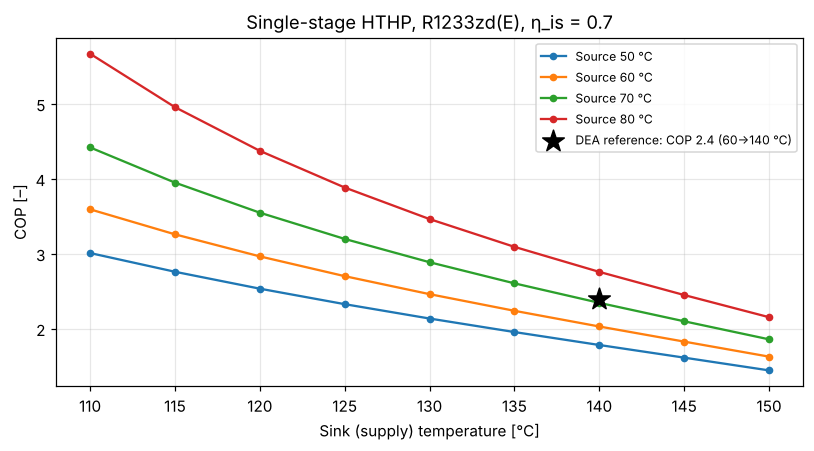

Carnot efficiency range: 0.37 to 0.58
Model COP at 60→140 °C: 2.03 vs DEA reference 2.4 (-15 %)


In [5]:
rows = [hp_cycle(Ts, Tk) for Ts in (50, 60, 70, 80) for Tk in range(110, 151, 5)]
cop_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for Ts, g in cop_df.groupby("T_source_C"):
    ax.plot(g["T_sink_C"], g["COP"], marker="o", ms=4, label=f"Source {Ts:.0f} °C")
ax.scatter([140], [2.4], marker="*", s=220, color="black", zorder=5,
           label="DEA reference: COP 2.4 (60→140 °C)")
ax.set_xlabel("Sink (supply) temperature [°C]")
ax.set_ylabel("COP [–]")
ax.set_title(f"Single-stage HTHP, {FLUID}, η_is = {P['eta_isentropic']}")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig1_cop.png", dpi=200); plt.show()

print("Carnot efficiency range:", cop_df["Carnot_eff"].min().round(2), "to", cop_df["Carnot_eff"].max().round(2))
print(f"Model COP at 60→140 °C: {ref['COP']:.2f} vs DEA reference 2.4 "
      f"({(ref['COP'] / 2.4 - 1) * 100:+.0f} %)")

The model comes out below the DEA reference. That is expected for a single-stage cycle with a 5 K pinch on each side, while commercial units use multi-stage compression, economisers or internal heat exchangers. The results below are therefore conservative for the heat pump.

## 4. Levelised cost of heat
LCOH = [CAPEX · CRF(r, n) + fixed O&M] / annual MWh per kW + variable O&M + energy cost

- Heat pump energy cost = p_el / COP
- Boiler energy cost = (p_gas + p_ETS · EF_gas) / η_boiler

,Heat pump,Gas boiler
Capital + fixed O&M,26.1,1.3
Variable O&M,4.1,1.3
Energy,90.6,65.4
CO2 (ETS),0.0,16.2


LCOH heat pump: 120.7 €/MWh | LCOH gas boiler: 84.2 €/MWh


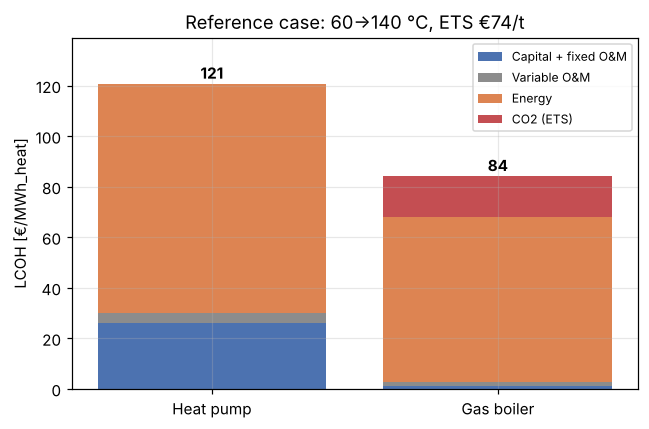

In [6]:
def crf(r, n):
    # Capital recovery factor: converts an upfront investment into an equal annual payment
    return r * (1 + r) ** n / ((1 + r) ** n - 1)

def fixed_cost_eur_MWh(capex, fom_share, lifetime, p=P):
    # Annualised CAPEX + fixed O&M, per MWh of heat (1 kW for FLH hours = FLH/1000 MWh)
    annual = capex * crf(p["discount_rate"], lifetime) + capex * fom_share
    return annual / (p["full_load_hours"] / 1000)

def lcoh_hp(cop, p=P):
    return (fixed_cost_eur_MWh(p["hp_capex_eur_kW"], p["hp_fom_share"], p["hp_lifetime_yr"], p)
            + p["hp_vom_eur_MWh"] + p["elec_price_eur_MWh"] / cop)

def lcoh_boiler(p=P):
    fuel_and_carbon = p["gas_price_eur_MWh"] + p["ets_price_eur_t"] * p["gas_ef_t_MWh"]
    return (fixed_cost_eur_MWh(p["boiler_capex_eur_kW"], p["boiler_fom_share"], p["boiler_lifetime_yr"], p)
            + p["boiler_vom_eur_MWh"] + fuel_and_carbon / p["boiler_efficiency"])

def lcoh_breakdown(cop, p=P):
    hp = {"Capital + fixed O&M": fixed_cost_eur_MWh(p["hp_capex_eur_kW"], p["hp_fom_share"], p["hp_lifetime_yr"], p),
          "Variable O&M": p["hp_vom_eur_MWh"],
          "Energy": p["elec_price_eur_MWh"] / cop,
          "CO2 (ETS)": 0.0}
    bo = {"Capital + fixed O&M": fixed_cost_eur_MWh(p["boiler_capex_eur_kW"], p["boiler_fom_share"], p["boiler_lifetime_yr"], p),
          "Variable O&M": p["boiler_vom_eur_MWh"],
          "Energy": p["gas_price_eur_MWh"] / p["boiler_efficiency"],
          "CO2 (ETS)": p["ets_price_eur_t"] * p["gas_ef_t_MWh"] / p["boiler_efficiency"]}
    return pd.DataFrame({"Heat pump": hp, "Gas boiler": bo})

bd = lcoh_breakdown(ref["COP"])
display(bd.round(1))
print(f"LCOH heat pump: {bd['Heat pump'].sum():.1f} €/MWh | LCOH gas boiler: {bd['Gas boiler'].sum():.1f} €/MWh")

fig, ax = plt.subplots(figsize=(6, 4))
bottom = np.zeros(2)
for comp, color in zip(bd.index, ["#4C72B0", "#8C8C8C", "#DD8452", "#C44E52"]):
    ax.bar(bd.columns, bd.loc[comp], bottom=bottom, label=comp, color=color)
    bottom += bd.loc[comp].values
for i, tot in enumerate(bottom):
    ax.text(i, tot + 2, f"{tot:.0f}", ha="center", fontweight="bold")
ax.set_ylabel("LCOH [€/MWh_heat]")
ax.set_title(f"Reference case: 60→140 °C, ETS €{P['ets_price_eur_t']:.0f}/t")
ax.legend(fontsize=8); ax.set_ylim(0, bottom.max() * 1.15)
plt.tight_layout(); plt.savefig("figures/fig2_lcoh_breakdown.png", dpi=200); plt.show()

## 5. Scenarios: carbon price × electricity/gas price ratio
ETS scenarios: the 2025 average (€74/t, ESMA), the 2030 analyst consensus (€126/t, GMK Center) and a 2035 forecast (€227/t nominal, LSEG). The gas price is held at the EU average, and the electricity price is varied through the price ratio.

,elec/gas ratio,ETS,LCOH HP,LCOH boiler,gap (HP − boiler)
0,2.0,€74 (2025 avg.),89.8,84.2,5.6
1,2.0,€126 (2030 consensus),89.8,95.6,-5.7
2,2.0,€227 (2035 LSEG),89.8,117.6,-27.8
3,3.0,€74 (2025 avg.),119.7,84.2,35.5
4,3.0,€126 (2030 consensus),119.7,95.6,24.1
5,3.0,€227 (2035 LSEG),119.7,117.6,2.1
6,4.0,€74 (2025 avg.),149.5,84.2,65.3
7,4.0,€126 (2030 consensus),149.5,95.6,53.9
8,4.0,€227 (2035 LSEG),149.5,117.6,31.9


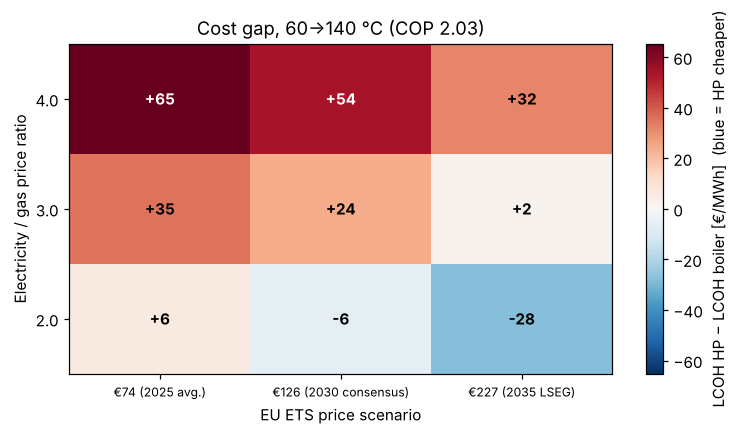

In [7]:
ets_scenarios = {"€74 (2025 avg.)": 74, "€126 (2030 consensus)": 126, "€227 (2035 LSEG)": 227}
ratio_scenarios = [2.0, 3.0, 4.0]   # electricity / gas price; EU average H2 2025 ≈ 3.0

rows = []
for ratio in ratio_scenarios:
    for label, ets in ets_scenarios.items():
        p = dict(P, ets_price_eur_t=ets, elec_price_eur_MWh=ratio * P["gas_price_eur_MWh"])
        hp, bo = lcoh_hp(ref["COP"], p), lcoh_boiler(p)
        rows.append({"elec/gas ratio": ratio, "ETS": label, "LCOH HP": hp, "LCOH boiler": bo, "gap (HP − boiler)": hp - bo})
scen = pd.DataFrame(rows)
display(scen.round(1))

grid = scen.pivot(index="elec/gas ratio", columns="ETS", values="gap (HP − boiler)")[list(ets_scenarios)]
lim = np.abs(grid.values).max()
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(grid.values, cmap="RdBu_r", vmin=-lim, vmax=lim, origin="lower", aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns, fontsize=8)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontweight="bold",
                color="white" if abs(v) > 0.6 * lim else "black")
ax.set_xlabel("EU ETS price scenario"); ax.set_ylabel("Electricity / gas price ratio")
fig.colorbar(im, label="LCOH HP − LCOH boiler [€/MWh]  (blue = HP cheaper)")
ax.set_title(f"Cost gap, 60→140 °C (COP {ref['COP']:.2f})")
plt.tight_layout(); plt.savefig("figures/fig3_scenarios.png", dpi=200); plt.show()

## 6. Break-even carbon price
The ETS price at which LCOH(HP) = LCOH(boiler):

p_ETS* = [(LCOH_HP − boiler non-fuel costs) · η_boiler − p_gas] / EF_gas

Break-even ETS price, reference case: €241/tCO2


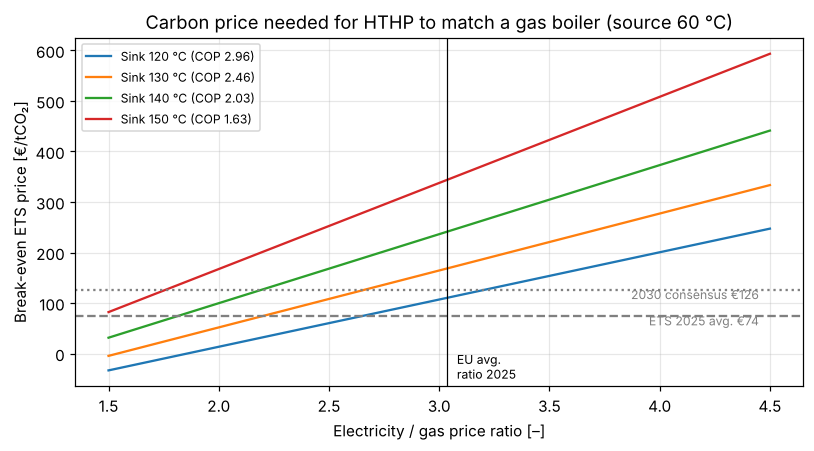

In [8]:
def breakeven_ets(cop, p=P):
    # ETS price at which LCOH(HP) = LCOH(boiler)
    boiler_non_fuel = fixed_cost_eur_MWh(p["boiler_capex_eur_kW"], p["boiler_fom_share"], p["boiler_lifetime_yr"], p) + p["boiler_vom_eur_MWh"]
    return ((lcoh_hp(cop, p) - boiler_non_fuel) * p["boiler_efficiency"] - p["gas_price_eur_MWh"]) / p["gas_ef_t_MWh"]

print(f"Break-even ETS price, reference case: €{breakeven_ets(ref['COP']):.0f}/tCO2")

ratios = np.linspace(1.5, 4.5, 61)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for Tk in (120, 130, 140, 150):
    c = hp_cycle(P["T_source_C"], Tk)["COP"]
    be = [breakeven_ets(c, dict(P, elec_price_eur_MWh=r * P["gas_price_eur_MWh"])) for r in ratios]
    ax.plot(ratios, be, label=f"Sink {Tk} °C (COP {c:.2f})")
ax.axhline(74, ls="--", color="grey"); ax.text(4.45, 56, "ETS 2025 avg. €74", fontsize=8, color="grey", ha="right")
ax.axhline(126, ls=":", color="grey"); ax.text(4.45, 108, "2030 consensus €126", fontsize=8, color="grey", ha="right")
ax.axvline(P["elec_price_eur_MWh"] / P["gas_price_eur_MWh"], color="k", lw=0.8)
ax.text(3.08, ax.get_ylim()[0] + 15, "EU avg.\nratio 2025", fontsize=8)
ax.set_xlabel("Electricity / gas price ratio [–]"); ax.set_ylabel("Break-even ETS price [€/tCO₂]")
ax.set_title("Carbon price needed for HTHP to match a gas boiler (source 60 °C)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig4_breakeven.png", dpi=200); plt.show()

## 7. Sensitivity analysis

,Break-even ETS [€/t]
Elec/gas ratio 2.0,100.0
"Full-load hours 8,000",199.0
CAPEX 1.20 M€/MW (≤125 °C unit),204.0
Compressor η_is 0.80,213.0
Base case,241.0
CAPEX 1.95 M€/MW (steam + lift add-ons),255.0
Discount rate 8 %,285.0
Elec/gas ratio 4.0,373.0


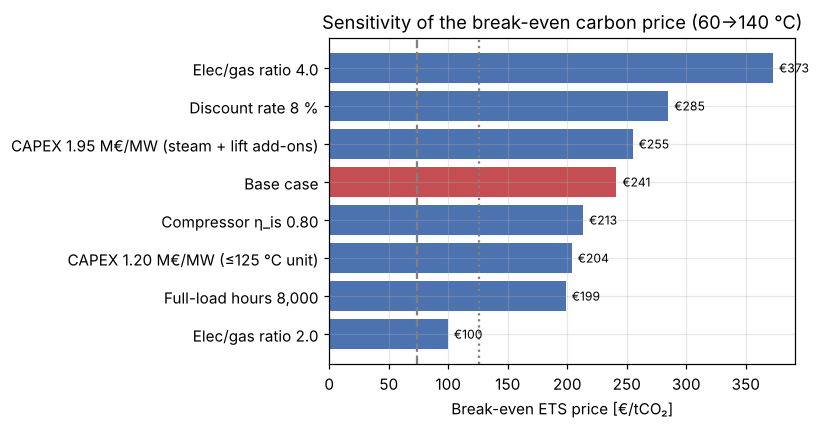

In [9]:
cases = {
    "Base case": {},
    "CAPEX 1.20 M€/MW (≤125 °C unit)": {"hp_capex_eur_kW": 1200},
    "CAPEX 1.95 M€/MW (steam + lift add-ons)": {"hp_capex_eur_kW": 1950},
    "Full-load hours 8,000": {"full_load_hours": 8000},
    "Discount rate 8 %": {"discount_rate": 0.08},
    "Elec/gas ratio 2.0": {"elec_price_eur_MWh": 2.0 * P["gas_price_eur_MWh"]},
    "Elec/gas ratio 4.0": {"elec_price_eur_MWh": 4.0 * P["gas_price_eur_MWh"]},
    "Compressor η_is 0.80": {"eta_isentropic": 0.80},
}
sens = {}
for name, change in cases.items():
    p = dict(P, **change)
    cop = hp_cycle(p["T_source_C"], p["T_sink_C"], p)["COP"]
    sens[name] = breakeven_ets(cop, p)
sens = pd.Series(sens).sort_values()
display(sens.round(0).to_frame("Break-even ETS [€/t]"))

fig, ax = plt.subplots(figsize=(7.5, 4))
colors = ["#C44E52" if k == "Base case" else "#4C72B0" for k in sens.index]
ax.barh(sens.index, sens.values, color=colors)
ax.axvline(74, ls="--", color="grey"); ax.axvline(126, ls=":", color="grey")
for i, v in enumerate(sens.values):
    ax.text(v + 5, i, f"€{v:.0f}", va="center", fontsize=8)
ax.set_xlabel("Break-even ETS price [€/tCO₂]")
ax.set_title("Sensitivity of the break-even carbon price (60→140 °C)")
plt.tight_layout(); plt.savefig("figures/fig5_sensitivity.png", dpi=200); plt.show()

## 8. Summary of key results

In [10]:
summary = {
    "COP (60→140 °C)": round(ref["COP"], 2),
    "LCOH heat pump [€/MWh]": round(lcoh_hp(ref["COP"]), 1),
    "LCOH gas boiler, ETS €74 [€/MWh]": round(lcoh_boiler(), 1),
    "Break-even ETS price [€/t]": round(breakeven_ets(ref["COP"])),
    "Elec/gas ratio needed at ETS €74": None,
}
# price ratio at which HP breaks even with today's ETS price
from scipy.optimize import brentq
f = lambda r: lcoh_hp(ref["COP"], dict(P, elec_price_eur_MWh=r * P["gas_price_eur_MWh"])) - lcoh_boiler()
summary["Elec/gas ratio needed at ETS €74"] = round(brentq(f, 0.5, 6), 2)
pd.Series(summary)

COP (60→140 °C)                       2.03
LCOH heat pump [€/MWh]              120.70
LCOH gas boiler, ETS €74 [€/MWh]     84.20
Break-even ETS price [€/t]          241.00
Elec/gas ratio needed at ETS €74      1.81
dtype: float64

## 9. Discussion
- **The electricity/gas price ratio is the dominant lever.** At the 2025 EU average ratio (~3.0), the heat pump needs a carbon price far above current ETS levels to reach parity. Lowering the ratio, for example by moving levies and network charges off electricity, has a stronger effect than any realistic ETS price increase.
- **Supply temperature matters.** Each extra 10 K of sink temperature cuts the COP and raises the break-even carbon price substantially, so sectors needing 120 °C are much closer to parity than those needing 150 °C or steam.
- **CAPEX and operating hours** move the result less than energy prices but still matter. Investment support and high-utilisation processes help.
- **Regulatory coverage gap:** combustion installations at or below 20 MW total rated thermal input fall outside EU ETS1 (Directive 2003/87/EC, Annex I), so many small and medium industrial boilers pay no ETS price at all. ETS2, which will cover fuels for such users, has been postponed to 2028.

## 10. Limitations
Single-stage cycle with constant efficiency; one refrigerant; constant annual-average prices (no hourly profiles or flexibility value); no grid connection costs; EU-average prices that hide large differences between countries; the HP CAPEX is held constant across sink temperatures; no taxes, subsidies or free allocation.